An **Artificial Neural Network (ANN)** is a machine learning model inspired by the structure and function of the human brain's biological neural networks. It forms the core foundation of deep learning, enabling algorithms to recognize complex patterns, learn from data, and make predictions.

![](https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcTBsmnsTMW7jj2CdPEvzm55aG-m8YqxP9oa_TfrNKACNzsw_qdlTdJiUJ-R&s=10)

---

## Network Architecture

An ANN consists of interconnected processing units called **nodes** (or artificial neurons) organized into distinct layers:

1. **Input Layer:** Receives raw features or data points from the external dataset.
2. **Hidden Layer(s):** Intermediate layers where feature extraction and computation occur. Simple ANNs (perceptrons) have one or two hidden layers, while deep neural networks contain many.
3. **Output Layer:** Produces the final prediction, classification category, or numerical output.

---

## Core Operational Mechanics

The forward processing and learning cycle follows four mathematical steps:

1. **Weighted Sum Calculation:** Each connection has an assigned weight ($w$), representing its signal strength, and a bias ($b$) offset. The node calculates:

$$Z = \sum (w_i \cdot x_i) + b$$


2. **Activation Function Application:** To learn non-linear relationships, the raw output $Z$ passes through an activation function $f(Z)$ such as **ReLU** ($f(x) = \max(0, x)$), **Sigmoid**, or **Softmax**.
3. **Loss Computation:** The network calculates the discrepancy between its prediction ($\hat{y}$) and the true label ($y$) using a loss function (e.g., Mean Squared Error or Cross-Entropy).
4. **Backpropagation & Optimization:** The error is propagated backward through the network using gradient descent to calculate partial derivatives and update weights:

$$w_{new} = w_{old} - \alpha \frac{\partial \text{Loss}}{\partial w}$$



*(where $\alpha$ is the learning rate)*.

---

## Primary ANN Architectures

| Architecture Type | Key Feature | Primary Use Case |
| --- | --- | --- |
| **Feedforward (FFNN)** | Information flows strictly forward without loops | Tabular data, simple regression/classification |
| **Convolutional (CNN)** | Spatial feature extractions via matrix kernels | Computer vision, image detection |
| **Recurrent (RNN / LSTM)** | Retains internal memory state across sequence steps | Time series, speech recognition, NLP |
| **Transformers** | Self-attention mechanisms replacing recurrence | Large language models, sequence processing |

---


---

## 1. ANN From Scratch (Using NumPy)

This implementation trains a simple 2-layer neural network to solve the **XOR problem**—a classic non-linear classification task that single-layer perceptrons cannot solve.

To understand the mechanics of an Artificial Neural Network, it is best to build one **from scratch using NumPy** (demonstrating forward pass and backpropagation directly). Afterward, we will look at how modern deep learning is implemented using **PyTorch**.

In [ ]:

import numpy as np

# Sigmoid activation function and its derivative
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):
    return x * (1 - x)

# Dataset: XOR Truth Table
# Inputs (X) and Expected Outputs (y)
X = np.array([[0, 0],
              [0, 1],
              [1, 0],
              [1, 1]])
y = np.array([[0],
              [1],
              [1],
              [0]])

# Set random seed for reproducibility
np.random.seed(42)

# Network Architecture Hyperparameters
input_neurons = 2
hidden_neurons = 4
output_neurons = 1
learning_rate = 0.5

# Initialize weights and biases randomly
W1 = np.random.uniform(size=(input_neurons, hidden_neurons))
b1 = np.zeros((1, hidden_neurons))
W2 = np.random.uniform(size=(hidden_neurons, output_neurons))
b2 = np.zeros((1, output_neurons))

# Training Loop
epochs = 10000
for epoch in range(epochs):
    # --- 1. Forward Pass ---
    layer1_input = np.dot(X, W1) + b1
    layer1_output = sigmoid(layer1_input)

    layer2_input = np.dot(layer1_output, W2) + b2
    predicted_output = sigmoid(layer2_input)

    # --- 2. Compute Loss (Mean Squared Error) ---
    error = y - predicted_output

    # --- 3. Backward Pass (Backpropagation) ---
    # Gradient at output layer
    d_predicted_output = error * sigmoid_derivative(predicted_output)

    # Error propagated to hidden layer
    error_layer1 = d_predicted_output.dot(W2.T)
    d_layer1 = error_layer1 * sigmoid_derivative(layer1_output)

    # --- 4. Update Weights and Biases (Gradient Descent) ---
    W2 += layer1_output.T.dot(d_predicted_output) * learning_rate
    b2 += np.sum(d_predicted_output, axis=0, keepdims=True) * learning_rate
    W1 += X.T.dot(d_layer1) * learning_rate
    b1 += np.sum(d_layer1, axis=0, keepdims=True) * learning_rate

# Display Final Results
print("Trained Predictions after 10,000 epochs:")
for actual, pred in zip(y, predicted_output):
    print(f"Target: {actual[0]} | Predicted: {pred[0]:.4f}")

Trained Predictions after 10,000 epochs:
Target: 0 | Predicted: 0.0191
Target: 1 | Predicted: 0.9843
Target: 1 | Predicted: 0.9845
Target: 0 | Predicted: 0.0155


### Explanation of the NumPy Implementation (XOR from Scratch)

This NumPy code demonstrates the complete underlying mathematical mechanics of an ANN by training a network with **one hidden layer (4 neurons)** to solve the non-linear XOR problem:

1. **Activation Function & Derivative:** The `sigmoid` function scales inputs to values between 0 and 1, introducing non-linearity. The `sigmoid_derivative` function calculates gradients needed for the backward pass.
2. **Parameter Initialization:** Weights (`W1`, `W2`) and biases (`b1`, `b2`) are initialized. Weights are set to small random values, while biases start at 0.
3. **Forward Pass:** Input data is multiplied by weights, bias is added, and the result is passed through the sigmoid activation function first to the hidden layer, and then onward to the output layer.
4. **Loss Calculation:** Calculates the error simply as the difference between target output $y$ and predicted output ($\hat{y}$).
5. **Backward Pass (Backpropagation):** Propagates the error backward through the network using the chain rule of calculus to compute how much each weight and bias contributed to the error.
6. **Gradient Descent:** Updates weights and biases using the learning rate parameter ($̑ = 0.5$) to minimize the prediction error over 10,000 iterations (epochs).

---

## 2. ANN Using PyTorch (Industry Standard)

In real-world applications, you don't write backpropagation manually. Frameworks like **PyTorch** handle autograd (automatic differentiation) and optimization out of the box.


In [ ]:

import torch
import torch.nn as nn
import torch.optim as optim

# Define the Neural Network Architecture
class SimpleANN(nn.Module):
    def __init__(self):
        super(SimpleANN, self).__init__()
        self.fc1 = nn.Linear(2, 4)     # Input to Hidden layer (2 inputs, 4 neurons)
        self.relu = nn.ReLU()          # Activation function
        self.fc2 = nn.Linear(4, 1)     # Hidden to Output layer (4 neurons, 1 output)
        self.sigmoid = nn.Sigmoid()    # Output activation for binary classification

    def forward(self, x):
        out = self.fc1(x)
        out = self.relu(out)
        out = self.fc2(out)
        out = self.sigmoid(out)
        return out

# Instantiate model, loss function, and optimizer
model = SimpleANN()
criterion = nn.BCELoss()                    # Binary Cross Entropy Loss
optimizer = optim.SGD(model.parameters(), lr=0.1) # Stochastic Gradient Descent

# Data Tensors
X = torch.tensor([[0.0, 0.0], [0.0, 1.0], [1.0, 0.0], [1.0, 1.0]])
y = torch.tensor([[0.0], [1.0], [1.0], [0.0]])

# Training Loop
for epoch in range(5000):
    optimizer.zero_grad()       # Clear previous gradients
    outputs = model(X)          # Forward pass
    loss = criterion(outputs, y)# Compute loss
    loss.backward()             # Backpropagation
    optimizer.step()            # Update weights

# Evaluate Model
with torch.no_grad():
    predictions = model(X)
    print("\nPyTorch Model Predictions:")
    print(predictions.numpy())




PyTorch Model Predictions:
[[6.2816136e-04]
 [9.9869543e-01]
 [9.9872440e-01]
 [1.1279052e-02]]


### Explanation of the PyTorch Implementation (Industry Standard)

This script performs the same XOR learning process, but utilizes the high-level **PyTorch framework** which abstracts away manual mathematics:

1. **Model Definition (`nn.Module`):** We define a neural network class `SimpleANN`. We construct linear transformation layers using `nn.Linear` and standard activation modules (`nn.ReLU` and `nn.Sigmoid`).
2. **Loss Function & Optimizer:** We configure standard loss models and optimizers. We use `nn.BCELoss` (Binary Cross-Entropy), which is more numerically stable than MSE for binary classification, and `optim.SGD` to handle parameter updates automatically.
3. **Gradient Management (`optimizer.zero_grad`):** PyTorch accumulates gradients across training passes by default. We must clear old gradients before starting the current pass.
4. **Autograd Engine (`loss.backward`):** Instead of calculating derivatives by hand, calling `.backward()` on our loss tensor triggers automatic differentiation throughout our model's computational graph.
5. **Parameter Update (`optimizer.step`):** Tells the optimizer to adjust weights and biases according to the computed gradients.

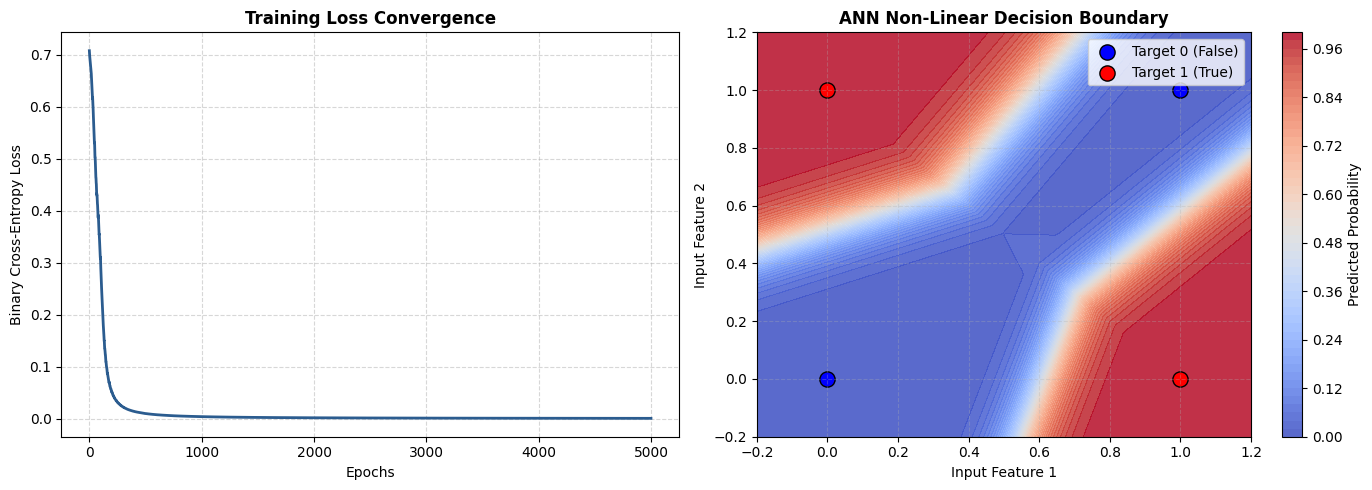

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

# 1. Define the Neural Network Architecture
class SimpleANN(nn.Module):
    def __init__(self):
        super(SimpleANN, self).__init__()
        self.fc1 = nn.Linear(2, 4)     # Hidden layer with 4 neurons
        self.relu = nn.ReLU()          # Non-linear activation
        self.fc2 = nn.Linear(4, 1)     # Output layer
        self.sigmoid = nn.Sigmoid()    # Binary classification activation

    def forward(self, x):
        return self.sigmoid(self.fc2(self.relu(self.fc1(x))))

# Initialize model, loss, and optimizer
model = SimpleANN()
criterion = nn.BCELoss()
optimizer = optim.SGD(model.parameters(), lr=0.5)

# XOR Dataset
X = torch.tensor([[0.0, 0.0], [0.0, 1.0], [1.0, 0.0], [1.0, 1.0]])
y = torch.tensor([[0.0], [1.0], [1.0], [0.0]])

# Training Loop with Loss Tracking
epochs = 5000
loss_history = []

for epoch in range(epochs):
    optimizer.zero_grad()
    outputs = model(X)
    loss = criterion(outputs, y)
    loss.backward()
    optimizer.step()
    loss_history.append(loss.item())

# 2. Graphical Visualizations using Matplotlib
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Plot 1: Training Loss Curve ---
axes[0].plot(range(epochs), loss_history, color='#2b5c8f', linewidth=2)
axes[0].set_title('Training Loss Convergence', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epochs', fontsize=10)
axes[0].set_ylabel('Binary Cross-Entropy Loss', fontsize=10)
axes[0].grid(True, linestyle='--', alpha=0.5)

# --- Plot 2: Decision Boundary for XOR ---
# Create a dense grid of points to evaluate the model's predictions
xx, yy = np.meshgrid(np.linspace(-0.2, 1.2, 200), np.linspace(-0.2, 1.2, 200))
grid_tensor = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)

with torch.no_grad():
    preds = model(grid_tensor).numpy().reshape(xx.shape)

# Contour plot for decision region
contour = axes[1].contourf(xx, yy, preds, levels=50, cmap='coolwarm', alpha=0.85)
fig.colorbar(contour, ax=axes[1], label='Predicted Probability')

# Scatter plot the actual XOR data points
X_np = X.numpy()
y_np = y.numpy().squeeze()
axes[1].scatter(X_np[y_np == 0, 0], X_np[y_np == 0, 1], color='blue', s=120, edgecolor='k', label='Target 0 (False)')
axes[1].scatter(X_np[y_np == 1, 0], X_np[y_np == 1, 1], color='red', s=120, edgecolor='k', label='Target 1 (True)')

axes[1].set_title('ANN Non-Linear Decision Boundary', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Input Feature 1', fontsize=10)
axes[1].set_ylabel('Input Feature 2', fontsize=10)
axes[1].legend(loc='upper right')
axes[1].grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

### Explanation of the Training Visualization

This section adds analysis and visualization tools using **Matplotlib** to inspect the performance and behavior of the PyTorch neural network:

1. **Loss Tracking:** During the training iterations, we store the current loss value using `loss.item()` and save it inside `loss_history` to track optimization progress over 5,000 epochs.
2. **Loss Convergence Curve (Left Plot):** A line chart plotting epoch counts against the loss value. This verifies that our model is successfully converging (optimizing) as the curve slopes downward towards 0.
3. **Decision Boundary Evaluation (Right Plot):**
    * We generate a dense grid coordinates (`xx`, `yy`) to cover our model's feature space.
    * The grid is passed through the trained model to calculate prediction probabilities for every coordinate.
    * `plt.contourf` generates a color-graded prediction field (blue indicating a predicted output of 0, and red indicating 1).
    * The true training data points are overlaid on top to visually confirm that the non-linear boundaries correctly isolate and classify the XOR points.